# IS 327 - Homework 1
### Everything you need to complete is marked by the word "TODO".
### Feel free to use generative AI to help you complete the homework but remember to declare your usage in the end

## Part 1: KNN Classification

### 1. Load breast cancer diagnostic dataset
Information of the dataset can be found here: https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-wisconsin-diagnostic-dataset

In [4]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

n_samples = cancer.target.shape[0]
print('number of samples:', n_samples)
print('input data size:', cancer.data.shape)
print('output data size:', cancer.target.shape)


number of samples: 569
input data size: (569, 30)
output data size: (569,)


Explore the dataset. Answer the following questions.

What is the data (X) we will use? What are the labels (y) we will use?

**TODO 1** (5 pt)

Answer: X will be the cancer.data column and y will be the cancer.target classifier (1 or 0/true or false)

### 2. Training test split (use ratio 8 : 2)

Split the whole dataset of 569 samples into X_train, y_train, X_test, and y_test using the ratio of 8:2.
There could be different choices of split percentages. We choose 8:2 in this assignment.

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, test_size=0.2, random_state=42)

### 3. Train KNN
Use KNeighborsClassifier from scikit-learn to train a classifier using X_train and y_train: 

https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

You can choose any value that you feel reasonable for k (n_neighbors).

In [7]:
from sklearn.neighbors import KNeighborsClassifier

neigh = KNeighborsClassifier(n_neighbors=3)
neigh.fit(X_train, y_train)
y_pred = neigh.predict(X_test)


What is the accuracy score of your classifer? Use accuracy_score from sklearn: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html

In [10]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy of KNN classifier (k=3):',accuracy)
#TODO 3 (5pt)


Accuracy of KNN classifier (k=3): 0.9298245614035088


### 4. Cross-validation to select hyperparmeter k

- Use cross-validation to find the best k value (from range 1 to 20)
- Use either scikit-learn's documentation or generative AI to discovery the best way to write the code for cross-validation

In [18]:
# TODO 4 (5 pt):
from sklearn.model_selection import cross_val_score
import numpy as np
k_values=range(1,20)
cv_values = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5)
    cv_values.append(scores.mean())
#print(cv_values)

best_k = k_values[np.argmax(cv_values)]
print(f'Best k found from cross-validation: {best_k}')


# Extract accuracy for k=9
k_9_index = 8  # Since k=9 is at index 8 (0-based index)
accuracy_k9 = cv_values[k_9_index]

print('Accuracy for k=9:',accuracy_k9)


Best k found from cross-validation: 9
Accuracy for k=9: 0.9274725274725274


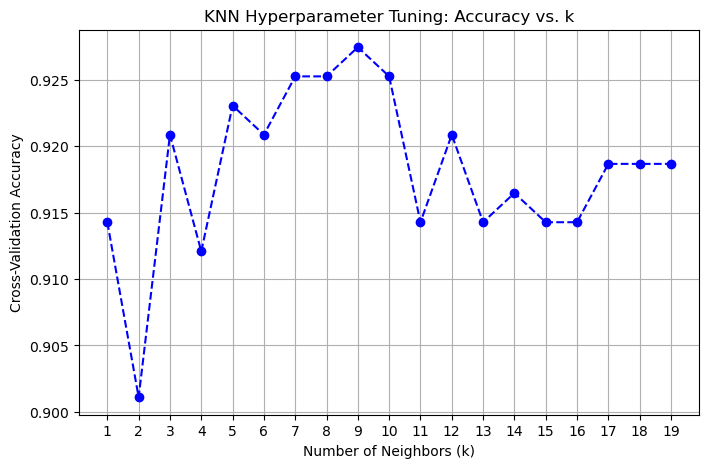

In [20]:
# Create a visualization of average accuracy versus k
# TODO 5 (5 pt)
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(k_values, cv_values, marker='o', linestyle='dashed', color='b')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Cross-Validation Accuracy')
plt.title('KNN Hyperparameter Tuning: Accuracy vs. k')
plt.xticks(k_values)
plt.grid(True)
plt.show()


In [21]:
# TODO 6 (5pt)
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train, y_train)
y_best_pred = best_knn.predict(X_test)
from sklearn.metrics import accuracy_score
best_accuracy = accuracy_score(y_test, y_best_pred)
print(f'Accuracy of KNN classifier with best k={best_k}: {best_accuracy:.4f}')



Accuracy of KNN classifier with best k=9: 0.9561


**TODO 7** (5pt)

Check the accuracy score of the best k from cross validation. Why does the accuracy scores change? Is it getting worse or better? What are the potential reasons that they differ?

Answer: The accuracy score for the best k from cross validation was lower than the one in TODO 6. This is because the cv accuracy is the average of the five different "cross sections" of the data we looked at, which reduces bias, but somewhat increases variability. On the test set, though, the model had never seen that data before, and it most modeled a real-world case of how the model would function. It had all 80% of the training portion of the data set to use for its prediction for the last 20%. 

## Part 2: Linear Regression

### 1. Load California Housing dataset
Information of the dataset can be found here: https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset

In [23]:
from sklearn.datasets import fetch_california_housing
import matplotlib.pyplot as plt

housing = fetch_california_housing(data_home='.')

n_samples = housing.target.shape[0]
print('number of samples:', n_samples)
print('input data size:', housing.data.shape)
print('output data size:', housing.target.shape)

print(housing.feature_names)

number of samples: 20640
input data size: (20640, 8)
output data size: (20640,)
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


Explore the dataset

**TODO 8** (5 pt)

Find the names of the eight features. And discuss how they can or cannot affect housing price?

https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html

Answer: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude

Average income can influence the cost of property in a given area. House age can raise or reduce the value of a home. The more bedrooms a house has the greater the value will be compared to their lower bedroom count counterparts. Average rooms often means either greater squarefootage or unique floorplans, which can both impact property value. Population in a given area can indicate things about tax revenue and therefore public school quality, which can raise value. Additionally, more rural areas often tend to have less expensive real estate. The average occupency of a house can often indicate size, with which property value often increases. Finally, latitude and longitude will indicate specific locations, and costs for houses often vary based on part of state, city, neighborhood, etc, so specific coordinates will give a great amount of specificity. 


### 2. Training test split (use ratio 8 : 2)

There could be different choices of split percentages. We choose 8:2 in this assignment.

In [24]:
# Split the whole dataset into a training set and a test set using the ratio of 8:2.
X_train, X_test, y_train, y_test = train_test_split(housing.data, housing.target, test_size=0.2, random_state=42)


### 3. Train linear regression

use LinearRegression from scikit-learn to fit a linear model using the train set
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

In [25]:
from sklearn.linear_model import LinearRegression

# TODO 9 (5 pt)
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)

### 4. Test regression

Note that evaluation metrics for classification and regression are different. 

https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics

Use R squared, MSE, MAE to evaluate regression performance.

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html


In [27]:
# TODO 10 (5 pt)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Compute evaluation metrics
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

# Print results
print(f'R² Score: {r2:.4f}')
print(f'Mean Squared Error: {mse:.4f}')
print(f'Mean Absolute Error: {mae:.4f}')


R² Score: 0.5758
Mean Squared Error: 0.5559
Mean Absolute Error: 0.5332


In [28]:
feature_names = housing.feature_names
coefficients = lin_reg.coef_
for feature, coef in zip(feature_names, coefficients):
    print(f'{feature}: {coef:.4f}')


MedInc: 0.4487
HouseAge: 0.0097
AveRooms: -0.1233
AveBedrms: 0.7831
Population: -0.0000
AveOccup: -0.0035
Latitude: -0.4198
Longitude: -0.4337


**TODO 11** (5 pt)

Interpret your model

Now check feature's coefficient against feature names. Do they make sense? (e.g., the price of a house should (usually) go up with the number of rooms)

Answer: This does not make a lot of sense. Prices should definitely not go down with occupancy. I am not so sure that latitude and longitude as a whole can reduce costs either. Perhaps it does make sense that more rooms reduce value if open concept is most desirable. I would expect population to have more of an impact and average occupancy to have a positive effect. 


**TODO 12** (5 pt)

We discussed in class that intercept is meaningful sometimes but not meaningful other times. Does the intercept make sense here? Give your explanations. 

Answer: This does not make sense in the context of house pricing since there cannot be a negative price. Perhaps this means that there is a different model better suited for what we are trying to find out. 

In [29]:
print(f"Intercept: {lin_reg.intercept_:.4f}")

Intercept: -37.0233


## Part 3: use Gradient Descent to solve the Linear Regression problem

We use the same housing dataset and the same train test split as part 2.

### 1. Rescale input data

Different input features (e.g., average number of rooms, block population, ...) can belong to really different ranges of values. In traditional machine learning models like linear regression, gradient descent is sensitive to data scaling. So, we rescale all input features to be in the range of [-1,1].

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

### 2. Train gradient-descent-based linear regression

use SGDRegressor from sklearn: 

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html

In [31]:
from sklearn.linear_model import SGDRegressor
sgd_reg = SGDRegressor(max_iter=1000, tol=1e-3, eta0=0.01, learning_rate="constant", random_state=42)
sgd_reg.fit(X_train, y_train)
y_sgd_pred = sgd_reg.predict(X_test)

# TODO 13 (5 pt)



### 3. Cross-validation to select hyperparameter learning rate

Learning rate is the step size (alpha in slides) in each gradient descent step.

- Use cross-validation to find the best learning rate (lr) (eta0 in SGDRegressor) value 
- from list [0.01, 0.003, 0.001, 3e-4, 1e-4, 1e-5] using average Accuracy. (1e-5 means 10 to the power of -5)

In [32]:
# TODO 14 (5 pt)
from sklearn.model_selection import cross_val_score
import numpy as np

# List of learning rates to test
learning_rates = [0.01, 0.003, 0.001, 3e-4, 1e-4, 1e-5]
cv_scores = {}

for lr in learning_rates:
    sgd = SGDRegressor(max_iter=1000, tol=1e-3, eta0=lr, learning_rate="constant", random_state=42)
    scores = cross_val_score(sgd, X_train, y_train, cv=5, scoring="r2")  # Use R² score
    cv_scores[lr] = scores.mean()  # Store average cross-validation score

# Find the best learning rate
best_lr = max(cv_scores, key=cv_scores.get)
print(f'Best learning rate found: {best_lr}')

# Print all learning rates with their corresponding R² scores
for lr, score in cv_scores.items():
    print(f'Learning rate {lr}: Cross-validation R² = {score:.4f}')




Best learning rate found: 0.0003
Learning rate 0.01: Cross-validation R² = -19464668264044630638592.0000
Learning rate 0.003: Cross-validation R² = -640840797359753527296.0000
Learning rate 0.001: Cross-validation R² = -3582808116.4731
Learning rate 0.0003: Cross-validation R² = 0.6119
Learning rate 0.0001: Cross-validation R² = 0.6092
Learning rate 1e-05: Cross-validation R² = 0.5609


In [33]:
# TODO 15 (5 pt)
# What is your selected best learning rate value with the highest cross-validation R squared score?

lr = 0.0003
print('My selected learning rate is:', lr)

My selected learning rate is: 0.0003


### 4. Test regression
Use R squared, MSE, MAE to evaluate regression performance.

In [35]:
# TODO 16 (5 pt)
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sgd_best = SGDRegressor(max_iter=1000, tol=1e-3, eta0=0.0003, learning_rate="constant", random_state=42)
sgd_best.fit(X_train, y_train)
y_sgd_best_pred = sgd_best.predict(X_test)

r2_sgd = r2_score(y_test, y_sgd_best_pred)
mse_sgd = mean_squared_error(y_test, y_sgd_best_pred)
mae_sgd = mean_absolute_error(y_test, y_sgd_best_pred)


print(f'R² Score: {r2_sgd:.4f}')
print(f'Mean Squared Error: {mse_sgd:.4f}')
print(f'Mean Absolute Error: {mae_sgd:.4f}')


R² Score: 0.5767
Mean Squared Error: 0.5546
Mean Absolute Error: 0.5376


**TODO 17** (5 pt)

Compare the three regressors you got: linear regression regressor, GD regression regressor with and without hyperparameter turning. What can you tell from the evaluation metrics?

The linear regression model was fine, not great but not bad. The SGD Regressor before we tuned it was a disaster; the predictions were unusable and it had enormous negative r^2 values. The model basically diverged instead of converging on a solution. Once tuned to 0.0003 though, it slightly improved the model compared to the linear regression, which is still not ideal, but better. 


# Part 4: Logistic Regression

Now we will revisit the cancer dataset and train a logistic regression classifier to classify cancer cell to Malignant or Benign

In [36]:
# load data
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

In [37]:
# split the dataset into train and test set (8:2)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, test_size=0.2, random_state=42)

Explore the documentation for the LogisticRegression class in sklearn:

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

Build a classifier. You can choose to use cross-validation and tune hyper parameters or not based on your proficiency with sklearn. However, I highly recommend that you will try it. 

In [39]:
# TODO 18 (5 pt)
# use logistic regression classifier to classify cancer cells using logistic regression. Hyperparameter tuning is optional. 
# report accuracy_score on the test dataset
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

log_reg = LogisticRegression(max_iter=5000, random_state=42)
log_reg.fit(X_train, y_train)

y_log_pred = log_reg.predict(X_test)

log_reg_accuracy = accuracy_score(y_test, y_log_pred)

print(f'Accuracy of Logistic Regression Classifier: {log_reg_accuracy:.4f}')



Accuracy of Logistic Regression Classifier: 0.9561


**TODO 19** (5 pt) 
What is the accuracy score on the test set for your previous KNN classifier? What is the accuracy score on the test set for your logistic regression classifier? Which one is better? 

Answer: Both the KNN classifier and the logistic regression models got a score of 95.61, which may indicate an error with how things were completed. There could be explanations for why this is valid as well. The logistic regression model is overall more efficient, so I would say that one is better overall.

**TODO 20** (5 pt)

Explore literatures and news about classifiers for cancer prediction. What did you find? What does the paper or news article make you think about the classifiers that you build?

Answer: https://pmc.ncbi.nlm.nih.gov/articles/PMC1282521/

This sounds like really interesting research; gene expression being used to determine cancerous properties is a great application of these concepts in a more complex way. It seems as though they are being careful with what biological samples are being used in testing versus training in just the abstract, so overall, seems like a promising field of research. It goes to show how important the classifiers are that we choose; there are so many options, but in choosing the best one available, the accuracy and impact of models can be incredibly large. 

## Reference

Cite the link to any material (e.g., tutorial, code) you use for this assignment.

All of the provided scikit-learn webpages. 

## Declare generative AI usage

If you used generative AI to help you complete the assignment, declare below with any reflections you have. 

- I used generative AI to check much of the code that I either wrote myself or got from the sklearn pages for accuracy and modified it as need
- For the questions that explicitly mention using AI or the literature to find the best way to solve the problem, I used both in those instances as well